In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn

In [2]:
from torch.utils.data import DataLoader, TensorDataset
from torch.nn import functional as F
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [3]:
DEVICE = torch.device("cpu")

In [4]:
digits = load_digits()

In [8]:
images_np = digits.images.astype("float32")
images_np = images_np / np.max(images_np)

In [ ]:
images_np

In [10]:
labels_clean = digits.target.astype("int64")

In [11]:
labels_clean

array([0, 1, 2, ..., 8, 9, 8], shape=(1797,))

In [12]:
images = torch.tensor(images_np[:,None,:,:]) #(N,1,8,8)

In [13]:
images.shape

torch.Size([1797, 1, 8, 8])

In [14]:
all_ids = np.arange(len(images))

80% - train -
 -  25% - val 55% - train


20% - test

In [15]:
train_va_ids, test_ids = train_test_split(all_ids, test_size=0.2, stratify = labels_clean,random_state=42)

In [16]:
train_pool_ids, val_ids = train_test_split(train_va_ids, test_size=0.25, stratify = labels_clean[train_va_ids],random_state=42)

In [18]:
rng = np.random.default_rng(42)
train_pool_ids = rng.permutation(train_pool_ids)

small_train_ids = train_pool_ids[:120]
latge_train_ids = train_pool_ids[:800]

In [19]:
#Deliberately corrupting 25% of labels in the Training pool only

labels_noisy = labels_clean.copy()
corrupted_ids = rng.choice(train_pool_ids, int(0.25*len(train_pool_ids)), replace=False)
labels_noisy[corrupted_ids] = rng.integers(0,10,len(corrupted_ids))

In [20]:
len(images)

1797

In [22]:
len(small_train_ids)

120

In [23]:
len(latge_train_ids)

800

In [24]:
#verify no data leakage
assert not set(train_pool_ids).intersection(set(val_ids))

In [25]:
class MLP(nn.Module):
  def __init__(self, small = False, dropout=False,num_classes =10):
    super().__init__()
    h1, h2 = (32,16) if small else (256,128)
    self.layers = nn.Sequential(
        nn.Flatten(),
        nn.Linear(64,h1), nn.ReLU(),
        nn.Dropout(0.4) if dropout else nn.Identity(),

        nn.Linear(h1,h2), nn.ReLU(),
        nn.Dropout(0.4) if dropout else nn.Identity(), #happens randomly

        nn.Linear(h2,num_classes)
    )
  def forward(self,x):
    return self.layers(x)

In [27]:
class SimpleCNN(nn.Module):
  def __init__(self, small = False, dropout=False,num_classes =10):
    super().__init__()
    c1, c2 = (8,16) if small else (32,64)
    hidden = 32 if small else 128
    self.features = nn.Sequential(
        nn.Conv2d(1,c1,3,padding=1), nn.ReLU(),
        nn.Conv2d(c1,c2,3,padding=1), nn.ReLU(),
        nn.Dropout2d(0.2) if dropout else nn.Identity(),
        nn.MaxPool2d(2),
        nn.Conv2d(c2,c2,3,padding=1), nn.ReLU(),
        nn.Dropout2d(0.2) if dropout else nn.Identity(),
        nn.MaxPool2d(2),
        nn.Flatten(),
        nn.Linear(c2*2*2,hidden), nn.ReLU(),
        nn.Dropout(0.4) if dropout else nn.Identity(),
    )
    self.classifer = nn.Linear(hidden,num_classes)
  def forward(self,x):
    return self.classifer(self.features(x))

numel() (short for number of elements) is a built-in function in PyTorch and MATLAB that returns the total number of individual elements inside a tensor or array, regardless of its dimensions

In [28]:
def count_params(model):
  return sum(p.numel() for p in model.parameters() if p.requires_grad)

In [65]:
def evalute(model, ids, labels):
  model.eval() #IMPORTANT: This disables dropout for evaluation
  with torch.inference_mode():
    y = torch.tensor(labels[ids], dtype=torch.long, device=DEVICE)
    y_pred = model(images[ids].to(DEVICE))
    logits = model(images[ids])
    loss = F.cross_entropy(logits, y).item()
    accuracy = (logits.argmax(1) == y).float().mean().item()
  return loss, accuracy

In [66]:
def augment_batch(x):
  n = x.shape[0]
  angle = (torch.rand(n)-0.5)*0.30 # small deg shift +/- 8.6degress
  tx = (torch.rand(n) - 0.5) * 0.14 # Small horizontal x shift
  ty = (torch.rand(n) - 0.5) * 0.14 # Small vertical y shift
  theta = torch.zeros(n,2,3)
  theta[:,0,0] = torch.cos(angle)
  theta[:,0,1] = -torch.sin(angle)
  theta[:,1,0] = torch.sin(angle)
  theta[:,1,1] = torch.cos(angle)
  theta[:,0,2] = tx
  theta[:,1,2] = ty
  grid = F.affine_grid(theta, x.shape,align_corners = False)
  return F.grid_sample(x,grid, align_corners=False, padding_model="zeros")

In [67]:
0.01, 0.001

(0.01, 0.001)

In [88]:
def fit(model, train_ids, train_labels, val_labels = labels_clean, epochs = 100, lr=0.003, weight_decay= 0.001,augment = False, patience=None):
  model = model.to(DEVICE)
  ds = TensorDataset(images[train_ids], torch.tensor(train_labels[train_ids], dtype=torch.long, device=DEVICE))
  loader = DataLoader(ds, batch_size=32, shuffle=True)
  optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay) #AdamW - Auto optimize weight decay
  history = []
  best_loss = float("inf")
  best_epoch = 0
  best_state = None
  stale_epochs = 0
  for epoch in range(epochs):
    model.train()
    for x,y in loader:
      if augment:
        x = augment_batch(x)
      optimizer.zero_grad()
      loss = F.cross_entropy(model(x.to(DEVICE)),y)
      loss.backward()
      optimizer.step()
    train_loss, train_acc = evalute(model, train_ids, train_labels)
    #print(train_acc)
    val_loss, val_acc = evalute(model, val_ids, val_labels)
    history.append(dict(epoch = epoch,train_loss=train_loss, train_acc= train_acc,val_loss = val_loss,val_acc =val_acc))
    if val_loss < best_loss-0.001:
      best_loss = val_loss
      best_epoch = epoch
      best_state = model.state_dict()
    else:
      #print(epoch)
      stale_epochs +=1
      if patience is not None and stale_epochs >= patience: #early stopping - if val_value does not change for a certain no. epoch (patience) - stop traning
        break
  if patience is not None and best_state is not None:
    model.load_state_dict(best_state)
  return {
          "model":model, "history": pd.DataFrame(history),
          "best_epoch": best_epoch, "best_loss": best_loss,
          "params": count_params(model)
    }

In [93]:
def plot_history(result, title):
  df = result["history"]
  #print(df)
  fig, axes = plt.subplots(1,2, figsize=(11,3.5))
  axes[0].plot(df.epoch, df.train_loss, label="train")
  axes[0].plot(df.epoch, df.val_loss, label="val")
  axes[0].set_xlabel("epoch")
  axes[0].set_ylabel("loss")
  axes[0].set(title = f"{title} - loss")
  axes[0].legend()
  axes[1].plot(df.epoch, df.train_acc*100, label="train")
  axes[1].plot(df.epoch, df.val_acc*100, label="val")
  axes[1].set(title = f"{title}: Accuracy", ylim=(0,105))

0.5166666507720947
0.574999988079071
0.699999988079071
0.8083333373069763
0.8500000238418579
0.875
0.9333333373069763
0.925000011920929
0.9666666388511658
0.9666666388511658
0.9833333492279053
0.9750000238418579
0.9750000238418579
0.9833333492279053
13
0.9916666746139526
0.9916666746139526
1.0
16
0.9916666746139526
17
1.0
18
1.0
19
1.0
20
1.0
21
1.0
22
1.0
23
1.0
24
1.0
25
1.0
26
1.0
27
1.0
28
1.0
29
1.0
30
1.0
31
1.0
32
1.0
33
1.0
34
1.0
35
1.0
36
1.0
37
1.0
38
1.0
39
1.0
40
1.0
41
1.0
42
1.0
43
1.0
44
1.0
45
1.0
46
1.0
47
1.0
48
1.0
49
1.0
50
1.0
51
1.0
52
1.0
53
1.0
54
1.0
55
1.0
56
1.0
57
1.0
58
1.0
59
1.0
60
1.0
61
1.0
62
1.0
63
1.0
64
1.0
65
1.0
66
1.0
67
1.0
68
1.0
69
1.0
70
1.0
71
1.0
72
1.0
73
1.0
74
1.0
75
1.0
76
1.0
77
1.0
78
1.0
79
1.0
80
1.0
81
1.0
82
1.0
83
1.0
84
1.0
85
1.0
86
1.0
87
1.0
88
1.0
89
    epoch  train_loss  train_acc  val_loss   val_acc
0       0    2.128574   0.516667  2.181606  0.369444
1       1    1.861825   0.575000  1.994362  0.419444
2       2    1.50

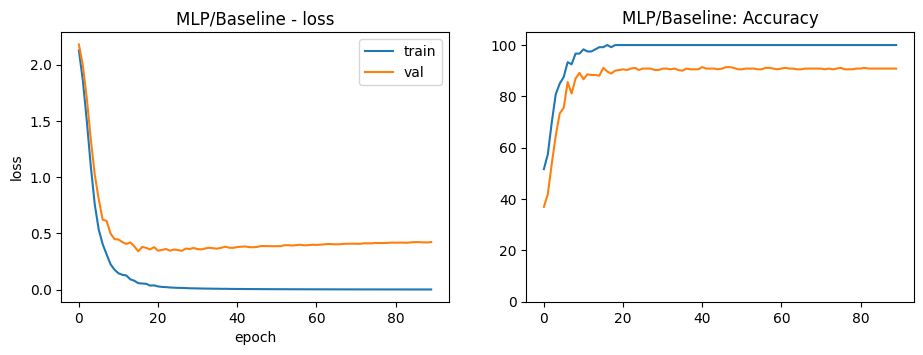

In [75]:
experiments = {}
experiments["MLP/Baseline"] = fit(MLP(), small_train_ids, labels_clean, epochs = 90)
plot_history(experiments["MLP/Baseline"], "MLP/Baseline")

0.23333333432674408
0.38333332538604736
0.5333333611488342
0.6166666746139526
0.6499999761581421
0.6666666865348816
0.6833333373069763
0.7083333134651184
0.7333333492279053
0.7416666746139526
0.7666666507720947
10
0.7749999761581421
0.800000011920929
0.8416666388511658
0.8500000238418579
0.8166666626930237
15
0.8500000238418579
16
0.875
0.8916666507720947
0.8916666507720947
19
0.9166666865348816
20
0.9333333373069763
21
0.925000011920929
22
0.9166666865348816
23
0.9416666626930237
24
0.9416666626930237
25
0.9666666388511658
26
0.9750000238418579
27
0.9583333134651184
28
0.9750000238418579
29
0.9833333492279053
30
0.9833333492279053
31
0.9833333492279053
32
1.0
33
1.0
34
1.0
35
1.0
36
1.0
37
1.0
38
1.0
39
1.0
40
1.0
41
1.0
42
1.0
43
1.0
44
1.0
45
1.0
46
1.0
47
1.0
48
1.0
49
1.0
50
1.0
51
1.0
52
1.0
53
1.0
54
1.0
55
1.0
56
1.0
57
1.0
58
1.0
59
1.0
60
1.0
61
1.0
62
1.0
63
1.0
64
1.0
65
1.0
66
1.0
67
1.0
68
1.0
69
1.0
70
1.0
71
1.0
72
1.0
73
1.0
74
1.0
75
1.0
76
1.0
77
1.0
78
1.0
79
1.0
80

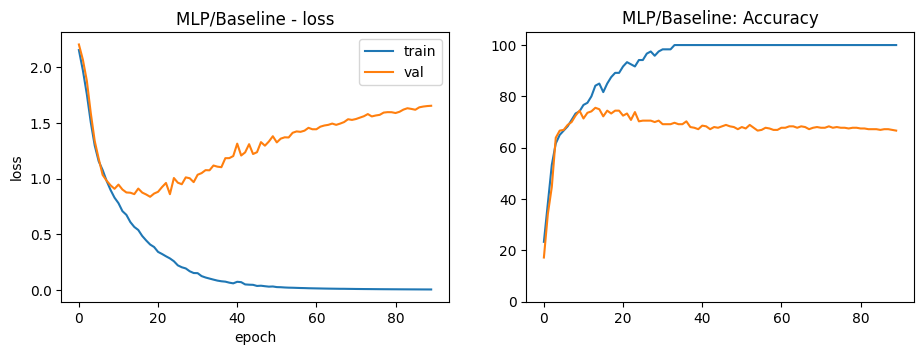

In [77]:
experiments = {}
experiments["MLP/Baseline"] = fit(MLP(), small_train_ids, labels_noisy, epochs = 90)
plot_history(experiments["MLP/Baseline"], "MLP/Baseline")

In [76]:
experiments

{'MLP/Baseline': {'model': MLP(
    (layers): Sequential(
      (0): Flatten(start_dim=1, end_dim=-1)
      (1): Linear(in_features=64, out_features=256, bias=True)
      (2): ReLU()
      (3): Identity()
      (4): Linear(in_features=256, out_features=128, bias=True)
      (5): ReLU()
      (6): Identity()
      (7): Linear(in_features=128, out_features=10, bias=True)
    )
  ),
  'history':     epoch  train_loss  train_acc  val_loss   val_acc
  0       0    2.128574   0.516667  2.181606  0.369444
  1       1    1.861825   0.575000  1.994362  0.419444
  2       2    1.501438   0.700000  1.701437  0.538889
  3       3    1.101073   0.808333  1.342269  0.647222
  4       4    0.760889   0.850000  1.023705  0.733333
  ..    ...         ...        ...       ...       ...
  85     85    0.001232   1.000000  0.422712  0.908333
  86     86    0.001200   1.000000  0.422424  0.908333
  87     87    0.001173   1.000000  0.420237  0.908333
  88     88    0.001153   1.000000  0.419677  0.908333
 

In [ ]:
experiments = {}
experiments["CNN/Baseline"] = fit(SimpleCNN(), small_train_ids, labels_clean, epochs = 90)
plot_history(experiments["CNN/Baseline"], "CNN/Baseline")

In [ ]:
experiments = {}
experiments["CNN/Baseline"] = fit(SimpleCNN(), small_train_ids, labels_noisy, epochs = 90)
plot_history(experiments["CNN/Baseline"], "CNN/Baseline")

In [84]:
drop = nn.Dropout2d(p=0.5)
drop.train()
example_maps = torch.ones(1,8,4,4) #8 feature maps of size 4x4
masked = drop(example_maps)

In [83]:
masked.mean(dim=(2,3)).numpy().round(1)

array([[2., 2., 0., 2., 0., 0., 2., 2.]], dtype=float32)

In [ ]:
#Droupout2D unlike standard dropout is randomly zeroing entire feature-map channel in a CNN.
#Its not the same as deleting or chainging the filter WeightedRandomSampler

In [89]:
mlp_cases = [
    ("MLP / Dropout", dict(dropout=True)),
    ("MLP / Small", dict(small=True)),
    ("MLP / Augment", dict(augment=True)),
    ("MLP / Early Stopping", dict(patience=10)),
    ("MLP / weight Decay", dict(weight_decay = 0.1))
]

In [94]:
for title, cfg in mlp_cases:
  cfg = cfg.copy()
  model = MLP(dropout=cfg.pop("dropout",False), small = cfg.pop("small",False))
  experiments[title] = fit(model, small_train_ids, labels_noisy, epochs= 50)
  result = experiments[title]
  df = result['history']

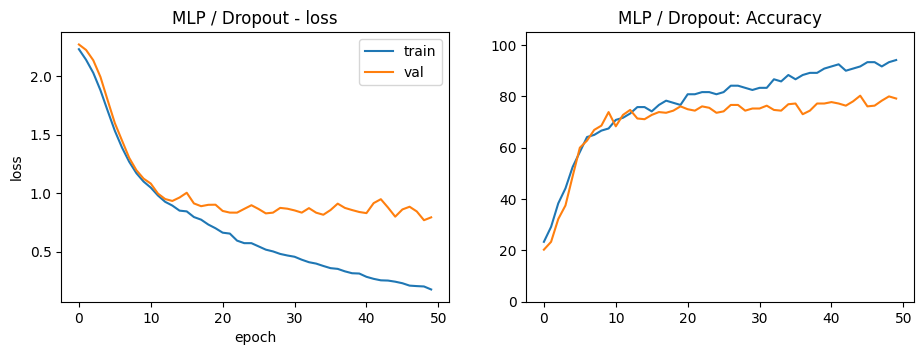

In [95]:
plot_history(experiments["MLP / Dropout"], "MLP / Dropout")

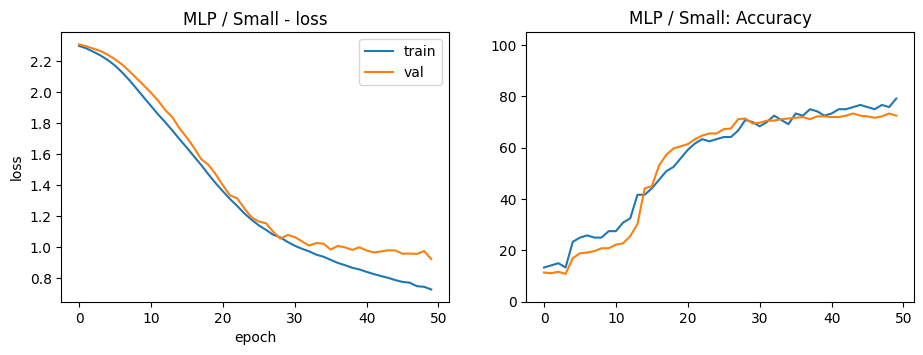

In [96]:
plot_history(experiments["MLP / Small"], "MLP / Small")

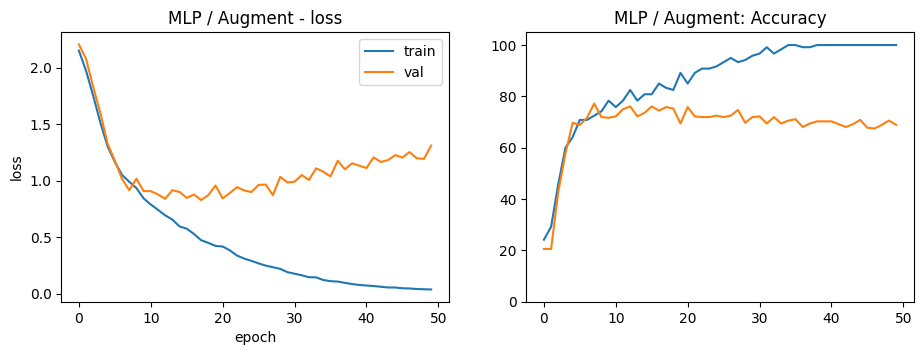

In [97]:
plot_history(experiments["MLP / Augment"], "MLP / Augment")

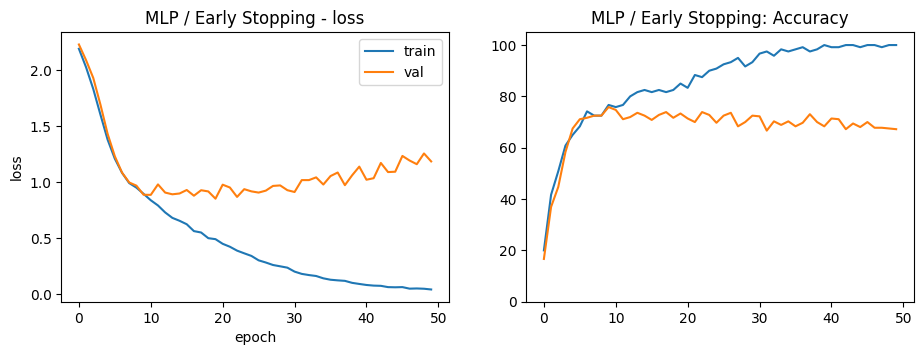

In [98]:
plot_history(experiments["MLP / Early Stopping"],"MLP / Early Stopping")

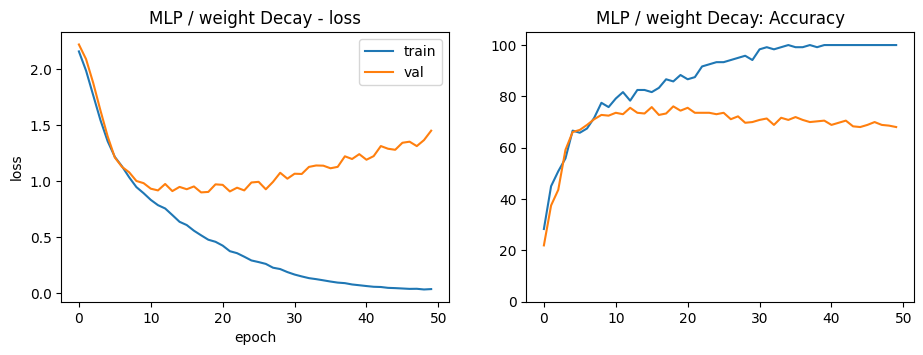

In [99]:
plot_history(experiments["MLP / weight Decay"],"MLP / weight Decay")

In [104]:
mlp_cases = [
    ("MLP / Dropout / largedata", dict(dropout=True)),
    ("MLP / Small / largedata", dict(small=True)),
]

In [105]:
for title, cfg in mlp_cases:
  cfg = cfg.copy()
  model = MLP(dropout=cfg.pop("dropout",False), small = cfg.pop("small",False))
  experiments[title] = fit(model, latge_train_ids, labels_clean, epochs= 100)
  result = experiments[title]
  df = result['history']

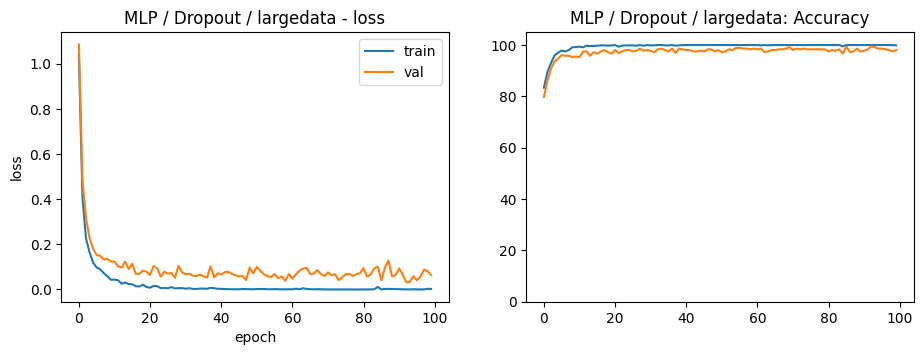

In [106]:
plot_history(experiments["MLP / Dropout / largedata"], "MLP / Dropout / largedata")

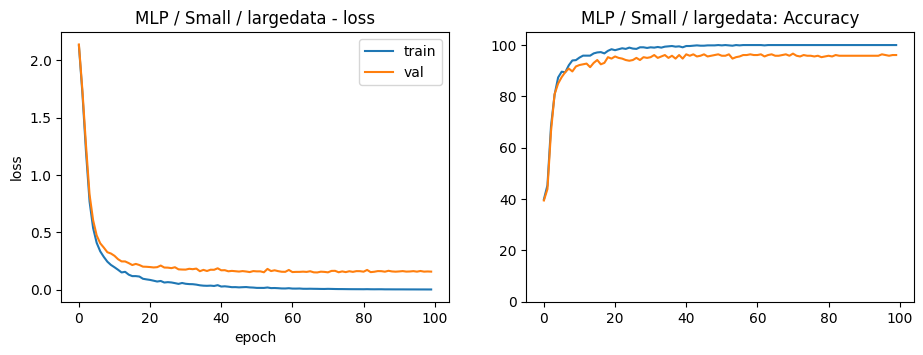

In [107]:
plot_history(experiments["MLP / Small / largedata"], "MLP / Small / largedata")

In [ ]:
#Assignment: Please tune the CNN - and find the correct setting..

In [ ]:
#NLP - audio